Python DA Assignment 2 - Data Visualization
1) Loading the Taxis Dataset

In [4]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Ans:Imported the Seaborn library and loaded the built-in Taxis dataset into a Pandas DataFrame named df.This dataset contains information about taxi trips,including distance,fare,tips,payment method and pickup location.

In [2]:
import seaborn as sns
df = sns.load_dataset("taxis")
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


2) Handling Missing Values
➢ Check for missing values in the dataset and identify columns with missing data.

Ans:checked the dataset for missing values and identified the columns containing them.

In [6]:
df.isnull().sum()

pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

➢ Impute missing values using appropriate strategies based on the column type (e.g,using mean, median, or mode for numerical columns, and mode for categorical columns).

Ans:Handled missing values using suitable methods(Mode),such as filling them with appropriate values. This helped improve the quality of the dataset before visualization.Rechecked if there is any missing values left.

In [7]:
df[['payment', 'pickup_zone', 'dropoff_zone',
    'pickup_borough', 'dropoff_borough']].mode().iloc[0]

payment                      credit card
pickup_zone               Midtown Center
dropoff_zone       Upper East Side North
pickup_borough                 Manhattan
dropoff_borough                Manhattan
Name: 0, dtype: str

In [8]:
df['payment'] = df['payment'].fillna(df['payment'].mode()[0])
df['pickup_zone'] = df['pickup_zone'].fillna(df['pickup_zone'].mode()[0])
df['dropoff_zone'] = df['dropoff_zone'].fillna(df['dropoff_zone'].mode()[0])
df['pickup_borough'] = df['pickup_borough'].fillna(df['pickup_borough'].mode()[0])
df['dropoff_borough'] = df['dropoff_borough'].fillna(df['dropoff_borough'].mode()[0])

In [9]:
df.isnull().sum()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

➢ For columns that are critical and cannot be reasonably imputed, remove rows with
missing values to maintain data integrity.

Ans:There are no remaining values that require row removal.The missing values in the categorical columns were filled using the mode.After cleaning,when checking the dataset there are no missing values remained.Therefore,no need of removing rows unnecessarily

3) Visualizations using Matplotlib/Pandas Plot:
★ Line Chart
Plot a line chart to visualize the fare over time, using the pickup timestamp as the
x-axis and fare as the y-axis. Ensure the pickup column is converted to a datetime
format before plotting.

Ans:A line chart was created using the pickup timestamp on the X-axis and fare on the Y-axis.Ensured the pickup column is converted to a datetime format before plotting.The data was sorted by pickup time to display the observations.An additional line chart was created to show the average fare for each day,making daily fare variations easier to understand.

In [13]:
df['pickup'].dtype

dtype('<M8[us]')

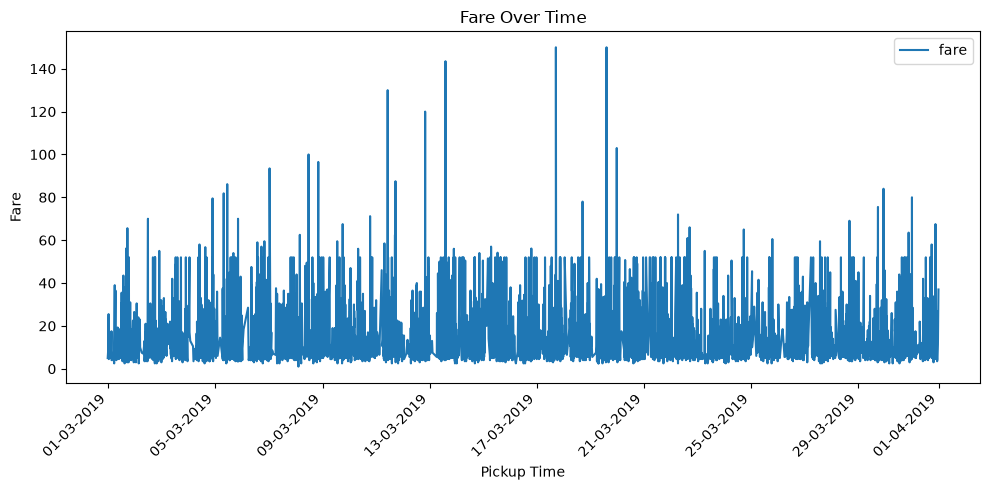

In [18]:
import matplotlib.dates as mdates
df_sorted = df.sort_values('pickup')
df_sorted.plot(x='pickup', y='fare', kind='line', figsize=(10, 5))
plt.title('Fare Over Time')
plt.xlabel('Pickup Time')
plt.ylabel('Fare')
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d-%m-%Y'))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

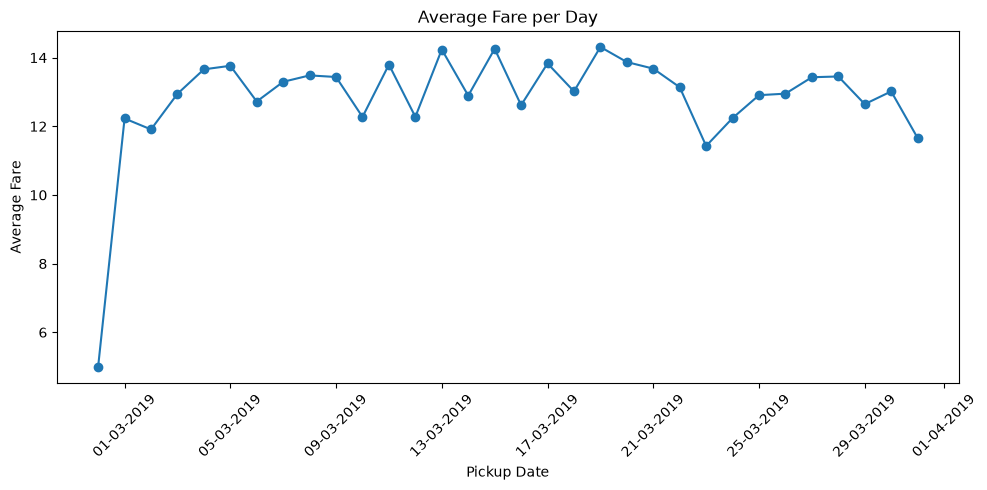

In [19]:
df_sorted['pickup_date'] = df_sorted['pickup'].dt.date
daily_fare = df_sorted.groupby('pickup_date')['fare'].mean()
daily_fare.plot(kind='line', figsize=(10, 5), marker='o')
plt.title('Average Fare per Day')
plt.xlabel('Pickup Date')
plt.ylabel('Average Fare')
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%d-%m-%Y'))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

★ Bar Chart
Create a bar chart to show the total fare for each pickup_borough. Group the data
by pickup_borough and sum the fare for each group.

Ans:A bar chart was created to compare the total fare across different boroughs.Manhattan recorded the highest total fare,while the Bronx recorded the lowest.

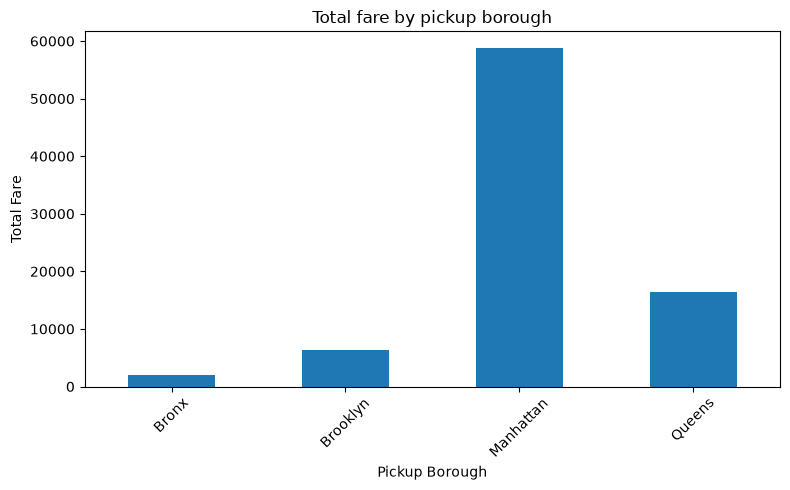

In [6]:
import matplotlib.pyplot as plt
borough_fare=df.groupby("pickup_borough")['fare'].sum()
borough_fare.plot(kind='bar',figsize=(8,5))
plt.title('Total fare by pickup borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

★ Pie Chart
Plot a pie chart showing the distribution of trips based on the payment method (credit
card, cash, etc.). Each slice should represent the count of trips for a specific payment
method.

Ans:Counted the number of trips for each payment method and created a pie chart.It shows the proportion of trips paid for using different methods, such as credit card and cash.

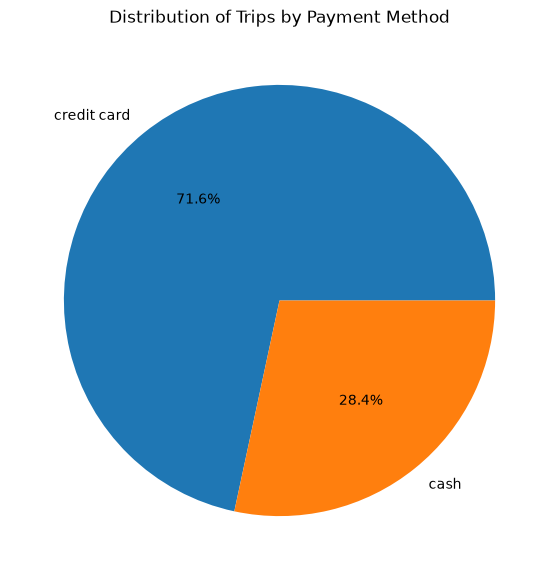

In [7]:
payment_counts = df['payment'].value_counts()
payment_counts.plot(kind='pie', autopct='%1.1f%%', figsize=(7, 7))
plt.title('Distribution of Trips by Payment Method')
plt.ylabel('')
plt.show()

★ Histogram
Create a histogram to visualize the distribution of distance. Customize the number of
bins for better granularity and ensure the plot is easy to interpret.

Ans:Created a histogram to visualize the distribution of trip distances.It helps identify the most common distance ranges among taxi trips.

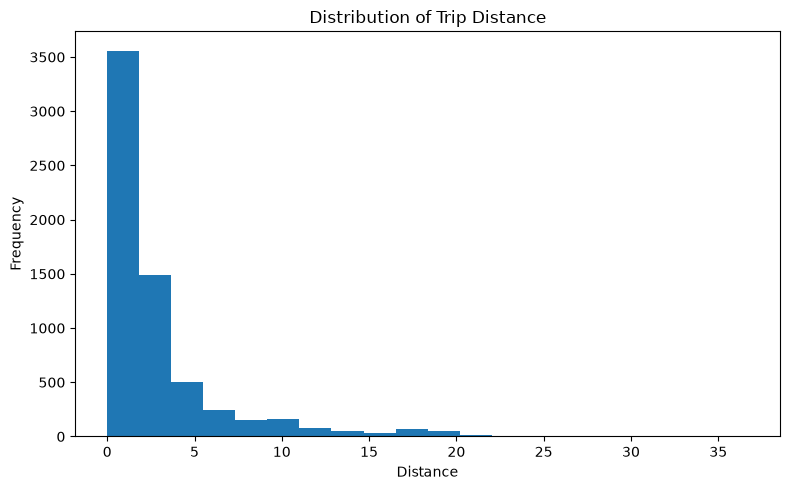

In [8]:
plt.figure(figsize=(8, 5))
df['distance'].plot(kind='hist', bins=20)
plt.title('Distribution of Trip Distance')
plt.xlabel('Distance')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

★ Box Plot
Plot a box plot to visualize the distribution of tip amounts for each pickup_borough.
Use pickup_borough as the categorical axis and tip as the numeric axis.

Ans:created a box plot to compare tip amounts across pickup boroughs.It helps identify the median,spread and possible outliers in tip values.

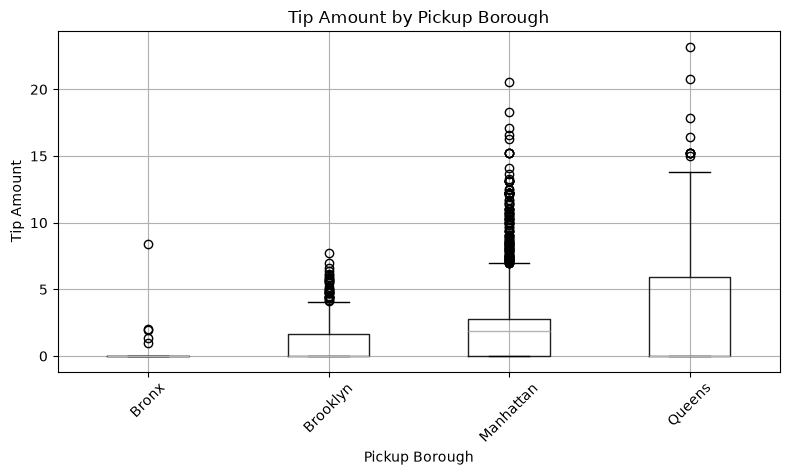

In [9]:
df.boxplot(column='tip', by='pickup_borough', figsize=(8,5))
plt.title('Tip Amount by Pickup Borough')
plt.suptitle('')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Visualizations using Seaborn:
★ Count Plot
Create a count plot to visualize the number of trips in each pickup_borough. The
x-axis should represent the boroughs, and the y-axis should show the count of trips.

Ans:Used a Seaborn count plot to display the number of trips in each pickup borough.It helps compare the trip counts across different boroughs.

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

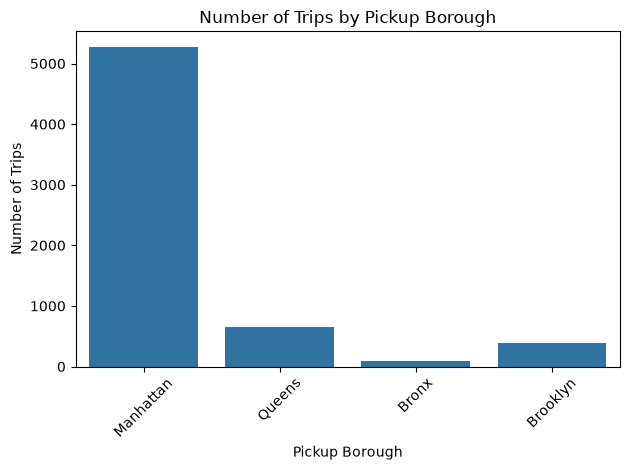

In [11]:
sns.countplot(data=df, x='pickup_borough')
plt.title('Number of Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

★ Scatter Plot
Plot a scatter plot to show the relationship between distance and fare. Use
distance on the x-axis and fare on the y-axis to visualize any correlation. Color the
points based on the pickup_borough to differentiate the trips by their respective
boroughs.

Ans:Created a scatter plot to show the relationship between trip distance and fare.Used different colours for pickup boroughs to compare trips from different locations.

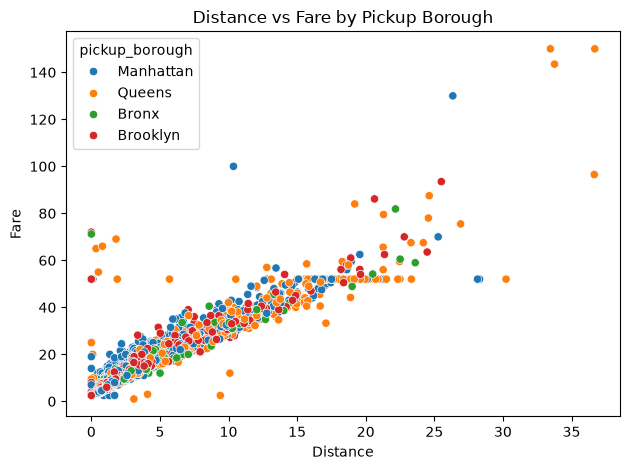

In [12]:
sns.scatterplot(data=df, x='distance', y='fare', hue='pickup_borough')
plt.title('Distance vs Fare by Pickup Borough')
plt.xlabel('Distance')
plt.ylabel('Fare')
plt.tight_layout()
plt.show()

★ Heatmap
Plot a heatmap to visualize the correlation between numerical variables such as
distance, fare, tip, tolls, and total. Use a correlation matrix to highlight the
relationships.

Ans:Created a correlation matrix for distance,fare,tip,tolls and total.The heatmap uses colours to show the strength and direction of relationships between these numerical variables.

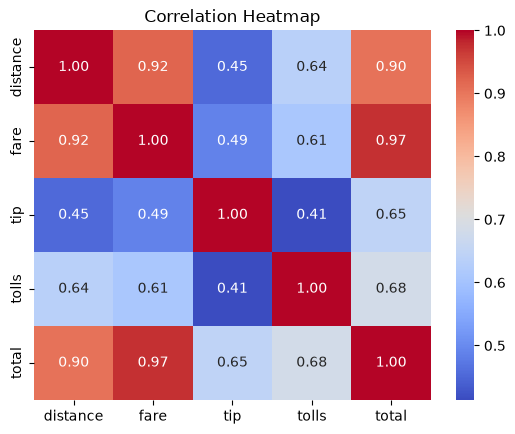

In [14]:
corr = df[['distance', 'fare', 'tip', 'tolls', 'total']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

★ Pair Plot
Create a pair plot to visualize the pairwise relationships between distance, fare, tip,
and total. Color the data points according to the pickup_zone method to compare
how different zones affect these variables.

Ans:Created a pair plot to visualize relationships between distance,fare,tip and total.Used different colours for pickup zones to compare patterns across different zones.Removed legend for a better output.

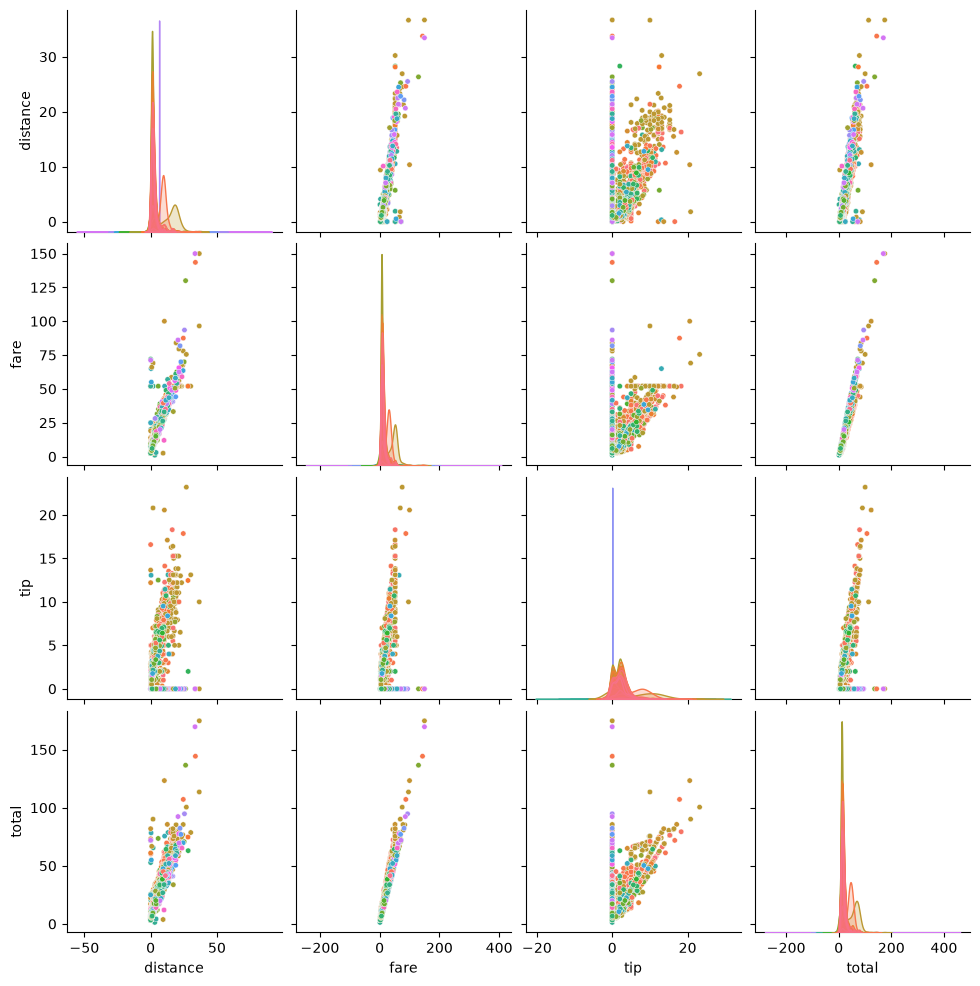

In [19]:
pair = sns.pairplot(
    df[['distance', 'fare', 'tip', 'total', 'pickup_zone']],
    hue='pickup_zone',
    plot_kws={'s': 15}
)
pair._legend.remove()
plt.show()

★ Violin Plot
Plot a violin plot to show the distribution of fare for each payment method. Use the
payment method as the categorical axis and fare as the numeric axis to visualize its
distribution.

Ans:Created a violin plot to visualize the distribution of fare amounts for each payment method.It helps compare the spread and concentration of fares for credit card and cash payments.

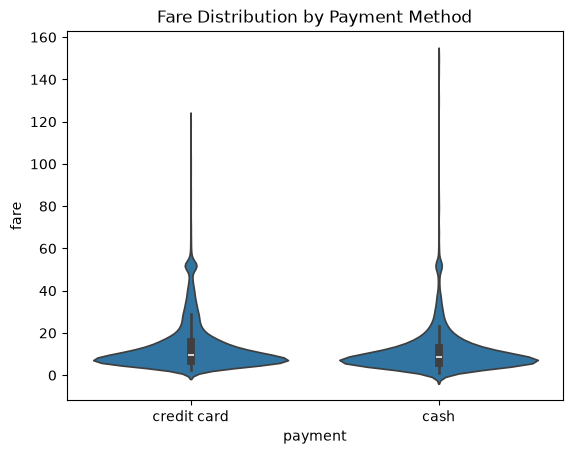

In [22]:
sns.violinplot(x='payment', y='fare', data=df)
plt.title('Fare Distribution by Payment Method')
plt.show()